In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from solve_dae.integrate import solve_dae
import numpy as np
from rfbmodel1D.parameters.params import SimulationParams, Vars
from rfbmodel1D.cells.cell import Cell
import matplotlib.pyplot as plt
import rfbmodel1D
import pandas as pd
import time

In [2]:
# ---------------------------------------------------------------------
# Setup: Create cell and initialize parameters
# ---------------------------------------------------------------------
sim_params = SimulationParams
sim_params.MeshParams.Uniform_M = True
sim_params.MembraneParams.thickness = 250e-6
cell = Cell(params=sim_params)
cell.bc_mode = "galvanostatic" # Set BC mode to galvanostatic
cell.modify_BC(Vars.phi_el, "cathode", "left", "galvanostatic", -1000)
print("Cathode superficial velocity:", cell.cathode.u_ip, "m/s", "Channel velocity:", cell.cathode.u_ch)
print("Total flow rate:", cell.cathode.Q_total, " m3/s", "Cathode flow rate:", cell.cathode.Q_ca, " m3/s")

Cathode superficial velocity: 0.0021796652426820675 m/s Channel velocity: 0.31084624272890565
Total flow rate: 7.5e-07  m3/s Cathode flow rate: 5.013230058168755e-07  m3/s


In [3]:
# ==============================================================================
# SIMULATION PARAMETERS 
# ==============================================================================
SOC    = 0.1                # [0-1] State of charge
V_tank = 0.5 / 1000         # [m³] Tank volume
i_io   = 5000 # A/m², example current density

In [4]:
# Derived tank concentrations from SOC
c_T_V4   = (1 - SOC) * 1000   # V(IV) concentration [mol/m³]
c_T_V5   = SOC * 1000         # V(V) concentration [mol/m³]
c_T_H    = 4963               # H+ concentration [mol/m³]
c_T_HSO4 = c_T_H * 3/5        # HSO4⁻ concentration [mol/m³]

# Tank state vector
c_0 = np.array([c_T_V4, c_T_V5, c_T_H, c_T_HSO4, V_tank])

# Initialize full DAE state from tank concentrations
# This will propagate the tank values through cathode, membrane, and anode

y0, yp0 = cell.initialize_dae_state(c_0, xtol=1e-6)

In [5]:
NM = cell.mesh.membrane_mesh.n_x
y0 = np.ones(NM) * 10      # creates a 1-D array of length NM
yp0 = np.zeros(NM)

In [6]:
t0, tf = 0, 1000
i_appl = [200, 400, 600, 800, 1000] # A/m²
lambda_sol = []
lam_eq  = cell.return_lambda_eq(0.95)
method  = "BDF"
for i in range(len(i_appl)):
    i_io = i_appl[i]
    def membrane_ode(t, y, yp):
        lam_eq_left  = lam_eq
        lam_eq_right = lam_eq
        res          = cell.water_transport_residual(t, y, yp, i_io=i_io, lam_eq_left=lam_eq_left, lam_eq_right=lam_eq_right)
        return res
    sol = solve_dae(
    membrane_ode,
    (t0, tf),
    y0,
    yp0,
    method=method)
    lambda_sol.append(sol.y[:,-1])

In [7]:

lam_profile = lambda_sol[-1]
l_membrane  = cell.membrane.thickness
dx_physical = cell.mesh.membrane_mesh.dx * l_membrane  # dx is normalized (0->1); convert to meters
D = cell.membrane_water_diffusivity(lam_profile, "hwang")
R_mem = np.sum(dx_physical / D)   # [m / (m²/s)] = [s/m]
D_eff = l_membrane / R_mem        # [m / (s/m)] = [m²/s]
print("Effective diffusivity:", D_eff, "m²/s")
k_eff = (1/cell.membrane.k_sorp_vw + 1/cell.membrane.k_ca_lw)**(-1)
print("Effective sorption coefficient:", k_eff, "m/s")
biot = k_eff * l_membrane / D_eff
print("Biot number:", biot)

Effective diffusivity: 2.623412467508442e-10 m²/s
Effective sorption coefficient: 1.8615875458429058e-05 m/s
Biot number: 17.740133975300203


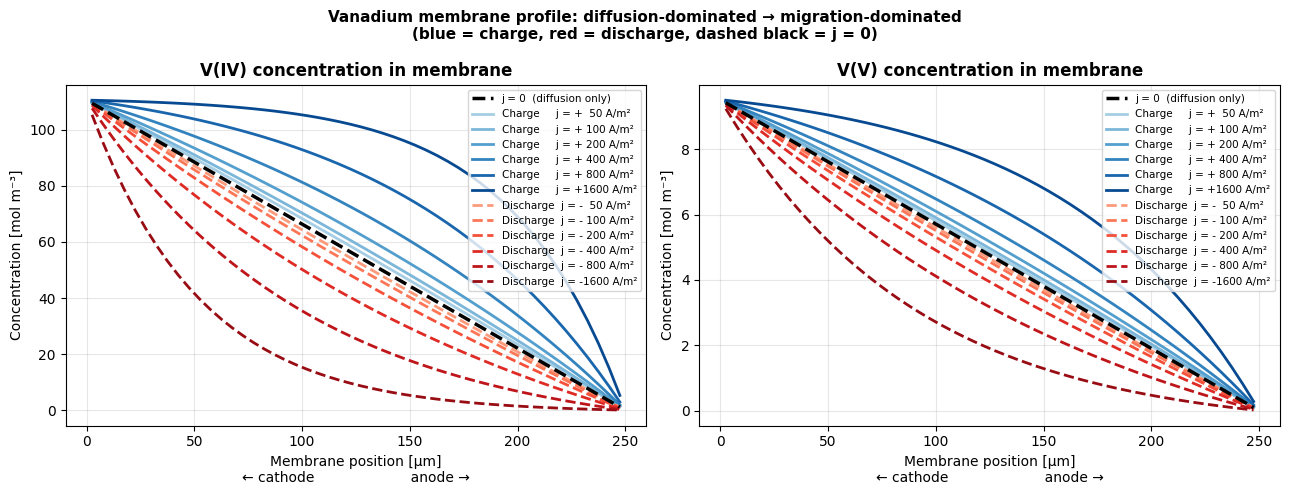

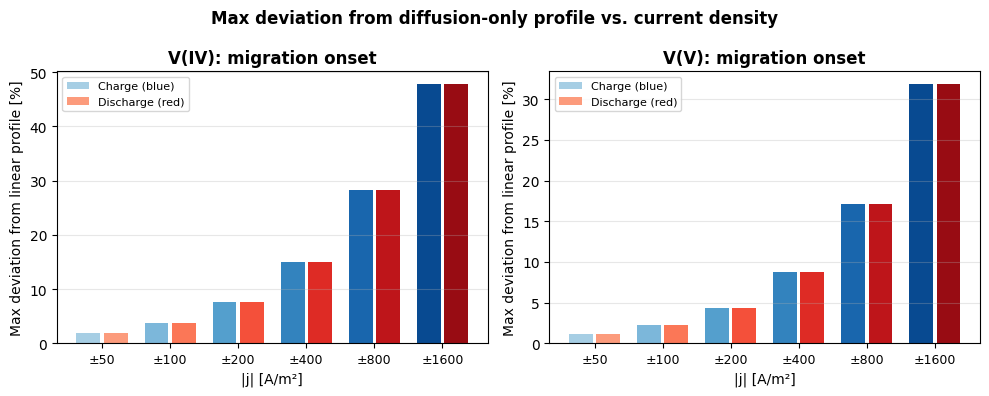

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from rfbmodel1D.parameters.params import Vars

# -- Current density sweep (charge > 0, discharge < 0) ------------------------
j_mag    = np.array([50, 100, 200, 400, 800, 1600])   # A/m²
j_sweep  = np.concatenate([-j_mag[::-1], [0], j_mag]) # discharge -> 0 -> charge

# -- Reference lambda from initial DAE state (y0 already computed above) -------
Nm       = cell.mesh.membrane_mesh.n_x
n_mem    = cell.layout.n_vars_membrane
n_ca     = cell.layout.n_vars_cathode
n_tank   = cell.layout.n_vars_tank
off_mem  = n_tank + cell.mesh.cathode_mesh.n_x * n_ca
lam_ref  = lam_profile

# -- Physical membrane x-coordinates [µm] -------------------------------------
dx_m      = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
edges_m   = np.concatenate([[0.0], np.cumsum(dx_m)])
x_mem_um  = 0.5 * (edges_m[:-1] + edges_m[1:]) * 1e6  # µm

# -- Sweep: update BC current -> call analytical kappa update -> store profiles --
j_orig = cell.bc[Vars.phi_el]["cathode"]["left"].value
V4_profiles, V5_profiles = {}, {}
for j in j_sweep:
    cell.modify_BC(Vars.phi_el, "cathode", "left", "galvanostatic", float(j))
    cell.update_kappa_io_m(lam_ref)
    V4_profiles[j] = cell.V4_profile.copy()
    V5_profiles[j] = cell.V5_profile.copy()
cell.modify_BC(Vars.phi_el, "cathode", "left", "galvanostatic", j_orig)  # restore

# -- Colormap: blue = charge (j>0), red = discharge (j<0) ---------------------
blues = plt.cm.Blues(np.linspace(0.35, 0.9, len(j_mag)))
reds  = plt.cm.Reds (np.linspace(0.35, 0.9, len(j_mag)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, profiles, species in zip(axes, [V4_profiles, V5_profiles], ["V(IV)", "V(V)"]):
    # j = 0 reference (pure diffusion -> linear profile)
    ax.plot(x_mem_um, profiles[0], "k--", lw=2.5, label="j = 0  (diffusion only)", zorder=5)
    # charge curves (j > 0)
    for k, j in enumerate(j_mag):
        ax.plot(x_mem_um, profiles[j],  color=blues[k], lw=2, label=f"Charge     j = +{j:4d} A/m²")
    # discharge curves (j < 0)
    for k, j in enumerate(j_mag):
        ax.plot(x_mem_um, profiles[-j], color=reds[k],  lw=2, label=f"Discharge  j = -{j:4d} A/m²", ls="--")

    ax.set_xlabel("Membrane position [µm]\n← cathode                      anode ->", fontsize=10)
    ax.set_ylabel("Concentration [mol m⁻³]")
    ax.set_title(f"{species} concentration in membrane", fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7.5, loc="best", ncol=1)

fig.suptitle(
    "Vanadium membrane profile: diffusion-dominated -> migration-dominated\n"
    "(blue = charge, red = discharge, dashed black = j = 0)",
    fontweight="bold", fontsize=11
)
plt.tight_layout()
plt.show()

# -- Deviation from linear (j=0) to quantify migration onset ------------------
fig2, axes2 = plt.subplots(1, 2, figsize=(10, 4))
for ax, profiles, species in zip(axes2, [V4_profiles, V5_profiles], ["V(IV)", "V(V)"]):
    ref = profiles[0]
    for k, j in enumerate(j_mag):
        dev_ch = np.max(np.abs(profiles[ j] - ref)) / (np.max(ref) + 1e-30) * 100
        dev_di = np.max(np.abs(profiles[-j] - ref)) / (np.max(ref) + 1e-30) * 100
        ax.bar(k - 0.2, dev_ch, 0.35, color=blues[k])
        ax.bar(k + 0.2, dev_di, 0.35, color=reds[k])
    ax.set_xticks(range(len(j_mag)))
    ax.set_xticklabels([f"±{j}" for j in j_mag], fontsize=9)
    ax.set_xlabel("|j| [A/m²]")
    ax.set_ylabel("Max deviation from linear profile [%]")
    ax.set_title(f"{species}: migration onset", fontweight="bold")
    ax.grid(True, alpha=0.3, axis="y")
    ax.legend(["Charge (blue)", "Discharge (red)"], fontsize=8)

fig2.suptitle("Max deviation from diffusion-only profile vs. current density", fontweight="bold")
plt.tight_layout()
plt.show()
